Notebook used to test methods to standardize data across DEMs and across storms. The methods are:
- Calculate MWL per timestep (avg across transect) & subtract
- Calculate MWL per transect over time & subtract
- Look up MWL from tide guage and subtract

Datasets being used in this analysis: 
- 1702827001820 (Dec 17, 2023 10:30 AM | 239 frames of data (frame 5 is technically null))
- add a later epoch in nor'easter
- grab from recent nor'easter

Most recent edits: BG 10/7/2026

In [1]:
import matplotlib.pyplot as plt
import numpy as np
#np.long = int 
import pandas as pd
import tensorflow as tf
import os
import glob
import mat73
import gc
from scipy.io import loadmat

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, losses
#from tensorflow.keras.datasets import fashion_mnist (fake data)
from tensorflow.keras.models import Model
from PIL import Image


import keras
from matplotlib.animation import FuncAnimation
import seaborn as sns
from scipy import signal
import re

2026-10-18 09:25:33.613087: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# paths  /Volumes/kanarde/MasonBEAST
modelsavepath=r'/Volumes/kanarde/MasonBEAST/data/trained_models/testing_standardization/'
savepath=r'/Volumes/kanarde/MasonBEAST/data/testingtime1/testing_standardization/'
transect_1702827001820_path=r'/Volumes/kanarde/MasonBEAST/data/DEMs/1702827001820/Transects/alongshore_transects.mat'

figpath1820=os.path.join(savepath,'1702827001820/Figures/')

Starting with the 1702827001820 dataset...

In [3]:
# Load Data
def loadNprep(training_datapath):
    # This function takes a path to a .mat file of transects in the form of a matrices (cross-shore pts x timesteps) 
    # imbedded in a larger structure (generated from ptcld2DEM2transects_process.m) and outputs dataframes of 
    # the transects
    raw_mat=loadmat(training_datapath)
    train_struct=raw_mat['tran_struct']

    all_trans=[]
    names=[]

    for elem in train_struct.ravel():
        name=elem['name'].item()
        data_matrix=elem['data']

        temp_df=pd.DataFrame(data_matrix)
        temp_df['name']=name

        all_trans.append(temp_df)
        names.append(name)

    train_trans_df=pd.concat(all_trans,axis=0,keys=names, names=['transect_name','original_index'])
    train_ds1=train_trans_df.drop(columns=['name'])
    print("Dataset 1 Shape:", train_ds1.shape)

    return train_ds1

In [4]:
def sort_transects(ds,descending=True):
    transects={transect_name:group.droplevel('transect_name') for transect_name,group in ds.groupby(level='transect_name')}
    print(f"{len(transects)} transects in given ds")
    import re
    # sort chronologicallly
    def extract_y_loc(name):
        match=re.search(r'y([-+]?\d+\.?\d*)',name)
        if match:
            return float(match.group(1))
        return 0
    sorted_transect_keys=sorted(transects.keys(),key=extract_y_loc,reverse=descending)
    sorted_transects={k:transects[k] for k in sorted_transect_keys}
    return sorted_transects

In [5]:
tran1702827001820=loadNprep(transect_1702827001820_path) # load
sorted_1820_dict=sort_transects(tran1702827001820,descending=True) #sort
sorted_1820=pd.concat(sorted_1820_dict.values(), keys=sorted_1820_dict.keys()) # dataframe

Dataset 1 Shape: (23693, 239)
43 transects in given ds


Grab transects through the DEM to test standardization teqniques

In [6]:
tran_7_3=sorted_1820.loc["transect_y7.3"]
tran_9_3=sorted_1820.loc["transect_y9.3"]
tran_neg4=sorted_1820.loc["transect_y-4"]
tran_21_3=sorted_1820.loc["transect_y21.3"]

print((tran_21_3.shape))

(551, 239)


In [7]:
def beach_elev(
    transect_matrix,
    region_start=100,
    region_end=200,
    window=120,
    quantile=0.1
):
    """
    Calculate a dynamic beach-face elevation line.

    Parameters
    ----------
    transect_matrix : pandas.DataFrame
        Rows = cross-shore positions
        Columns = timesteps

    region_start : int
        Starting cross-shore index of the beach-face region.

    region_end : int
        Ending cross-shore index of the beach-face region.

    window : int
        Number of previous frames used to calculate the beach face.
        120 frames = 1 minute if the data are sampled at 2 frames/second.

    quantile : float
        Quantile used to identify the lower-elevation values.
        0.1 = lowest 10%.

    Returns
    -------
    beachface : pandas.DataFrame
        Rows = cross-shore positions 100–200
        Columns = timesteps

        Each column is the dynamic beach-face profile for that timestep.
    """

    # Select beach-face region
    beach_region = transect_matrix.iloc[
        region_start:region_end + 1, :
    ].copy()

    # Make sure values are numeric
    beach_region = beach_region.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Output DataFrame
    beachface = pd.DataFrame(
        index=beach_region.index,
        columns=transect_matrix.columns,
        dtype=float
    )

    # Loop through each timestep
    for i, t in enumerate(transect_matrix.columns):

        # Previous 120 frames, including current frame
        start = max(0, i - window + 1)

        time_window = beach_region.iloc[:, start:i + 1]

        # Calculate low-elevation value at each cross-shore position
        beachface[t] = time_window.quantile(
            quantile,
            axis=1
        )

    return beachface

In [8]:
def runup_extent(transect_matrix, beachface, threshold=0.03):
    """
    Calculate runup extent for each timestep using a dynamic,
    spatially varying beach-face elevation.

    Parameters
    ----------
    transect_matrix : pandas.DataFrame
        Rows = cross-shore positions
        Columns = timesteps.

    beachface : pandas.DataFrame
        Dynamic beach-face elevations.
        Rows = cross-shore positions
        Columns = timesteps.

    threshold : float
        Elevation above beach face used to identify water/runup.
        Default = 0.03 m (3 cm).

    Returns
    -------
    runup : pandas.Series
        Maximum cross-shore position where the transect is
        more than threshold above the beach face.
    """

    runup = pd.Series(
        index=transect_matrix.columns,
        dtype=float
    )

    # Make sure beachface has the same cross-shore index
    beachface = beachface.reindex(
        index=transect_matrix.index,
        columns=transect_matrix.columns
    )

    for t in transect_matrix.columns:

        z = pd.to_numeric(
            transect_matrix[t],
            errors="coerce"
        )

        bf = pd.to_numeric(
            beachface[t],
            errors="coerce"
        )

        # Water/runup is elevation > beach face + threshold
        above_beach = (
            (z - bf) > threshold
        )

        # Only use locations where both are valid
        valid = (
            above_beach &
            z.notna() &
            bf.notna()
        )

        if valid.any():
            runup.loc[t] = valid[valid].index.max()
        else:
            runup.loc[t] = np.nan

    return runup

In [9]:
beachface_7_3=beach_elev(tran_7_3,100,200,window=120)
runup_7_3=runup_extent(tran_7_3,beachface_7_3)

**Method 1: Calculate the MWL (spatial avg per timestep per transect) and subtract)**

In [38]:
def MWL_per_time(transect_matrix, runup_extent):

    MWL_tstep = []

    displacement = pd.DataFrame(
        index=transect_matrix.index,
        columns=transect_matrix.columns,
        dtype=float
    )

    # Cross-shore coordinates
    x = pd.to_numeric(
        transect_matrix.index,
        errors="coerce"
    ).to_numpy(dtype=float)

    for t in transect_matrix.columns:

        # Runup location for this timestep
        r = runup_extent.loc[t]

        # --------------------------------------------------
        # No valid runup
        # --------------------------------------------------

        if pd.isna(r):
            MWL_tstep.append(np.nan)
            displacement[t] = np.nan
            continue

        r = float(r)

        # --------------------------------------------------
        # Find nearest cross-shore row to runup
        # --------------------------------------------------

        valid_x = np.isfinite(x)

        if not valid_x.any():
            MWL_tstep.append(np.nan)
            displacement[t] = np.nan
            continue

        valid_positions = np.where(valid_x)[0]

        nearest_position = valid_positions[
            np.argmin(
                np.abs(x[valid_positions] - r)
            )
        ]

        # --------------------------------------------------
        # Get transect elevations from runup onward
        # --------------------------------------------------

        aeta = pd.to_numeric(
            transect_matrix.iloc[
                nearest_position:,
                transect_matrix.columns.get_loc(t)
            ],
            errors="coerce"
        )

        # --------------------------------------------------
        # Calculate MWL
        # --------------------------------------------------

        MWL = aeta.mean()

        MWL_tstep.append(MWL)

        # --------------------------------------------------
        # Calculate net displacement
        # --------------------------------------------------

        displacement[t] = (
            pd.to_numeric(
                transect_matrix[t],
                errors="coerce"
            ) - MWL
        )

    # ------------------------------------------------------
    # Convert MWL to Series
    # ------------------------------------------------------

    MWL_tstep = pd.Series(
        MWL_tstep,
        index=transect_matrix.columns,
        dtype=float
    )

    return MWL_tstep, displacement

In [39]:
MWL_7_3,displacement_7_3=MWL_per_time(tran_7_3,runup_7_3)

In [40]:
print(tran_7_3.shape)
print(displacement_7_3.shape)
print(beachface_7_3.shape)

(551, 239)
(551, 239)
(101, 239)


In [41]:
def plot_net_displacement(
    transect_matrix,
    net_displacement,
    MWL,
    runup_extent,
    beach_face,
    interval=100,
    save_path=None,
):
    """
    Animate:
        Top:    transect, MWL line, dynamic beach face, runup point (max elevation capped at 8m)
        Bottom: net displacement (always plotted; values LEFT of runup masked as NaN when available)

    Transect orientation:
        rows    = cross-shore positions
        columns = timesteps
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.animation import FuncAnimation

    # ---------------------------------------------------------
    # 1. Clean, numericize, and sort cross-shore coordinates
    # ---------------------------------------------------------
    transect_matrix = transect_matrix.copy()
    transect_matrix.index = pd.to_numeric(transect_matrix.index, errors="coerce")
    transect_matrix = transect_matrix.sort_index()

    x = transect_matrix.index.to_numpy(dtype=float)
    timesteps = transect_matrix.columns

    # Helper function to convert scalar/Series/DataFrame inputs cleanly
    def _to_series(val, t_cols):
        if isinstance(val, (int, float, np.number)):
            return pd.Series(float(val), index=t_cols)
        elif isinstance(val, pd.Series):
            return val.reindex(t_cols)
        elif isinstance(val, pd.DataFrame):
            return val.iloc[0].reindex(t_cols)
        else:
            return pd.Series(val, index=t_cols)

    mwl_series = _to_series(MWL, timesteps)
    runup_series = _to_series(runup_extent, timesteps)

    # ---------------------------------------------------------
    # 2. Reindex inputs to match sorted transect
    # ---------------------------------------------------------
    net_displacement = net_displacement.reindex(
        index=transect_matrix.index,
        columns=timesteps
    )

    beach_face = beach_face.copy()
    beach_face.index = pd.to_numeric(beach_face.index, errors="coerce")
    beach_face = beach_face.sort_index().reindex(columns=timesteps)
    beachface_x = beach_face.index.to_numpy(dtype=float)

    # ---------------------------------------------------------
    # 3. Y-Limits Pre-calculation
    # ---------------------------------------------------------
    # Top plot min elevation calculation
    all_elev = transect_matrix.to_numpy(dtype=float)
    all_beach = beach_face.to_numpy(dtype=float)
    all_mwl = pd.to_numeric(mwl_series, errors="coerce").to_numpy(dtype=float)

    valid_elev_all = all_elev[np.isfinite(all_elev)]
    valid_beach_all = all_beach[np.isfinite(all_beach)]
    valid_mwl_all = all_mwl[np.isfinite(all_mwl)]

    combined_elev = np.concatenate([
        valid_elev_all if len(valid_elev_all) > 0 else [0],
        valid_beach_all if len(valid_beach_all) > 0 else [0],
        valid_mwl_all if len(valid_mwl_all) > 0 else [0]
    ])
    y1_min = np.nanmin(combined_elev)
    y1_pad = (8.0 - y1_min) * 0.05 if 8.0 > y1_min else 0.5
    y1_bottom = y1_min - y1_pad

    # Bottom plot (displacement) y-limits calculated globally across all timesteps
    disp_matrix = net_displacement.to_numpy(dtype=float).copy()
    disp_masked_matrix = disp_matrix.copy()

    for col_idx, t in enumerate(timesteps):
        rx = runup_series.loc[t]
        if pd.notna(rx):
            disp_masked_matrix[x < float(rx), col_idx] = np.nan

    valid_disp_all = disp_masked_matrix[np.isfinite(disp_masked_matrix)]
    if len(valid_disp_all) == 0:
        valid_disp_all = disp_matrix[np.isfinite(disp_matrix)]

    if len(valid_disp_all) > 0:
        y2_min, y2_max = np.nanmin(valid_disp_all), np.nanmax(valid_disp_all)
        y2_pad = (y2_max - y2_min) * 0.1 if y2_max != y2_min else 0.1
    else:
        y2_min, y2_max, y2_pad = -0.1, 0.1, 0.05

    # ---------------------------------------------------------
    # 4. Figure & Axes Setup
    # ---------------------------------------------------------
    fig, (ax1, ax2) = plt.subplots(
        2,
        1,
        figsize=(11, 8),
        sharex=True
    )

    # Set top plot max elevation strictly to 8m
    ax1.set_ylim(bottom=y1_bottom, top=8.0)
    ax2.set_ylim(y2_min - y2_pad, y2_max + y2_pad)

    # =========================================================
    # FIRST FRAME INITIALIZATION
    # =========================================================
    t0 = timesteps[0]

    # Transect
    elev0 = pd.to_numeric(
        transect_matrix[t0],
        errors="coerce"
    ).to_numpy(dtype=float)

    transect_line, = ax1.plot(
        x,
        elev0,
        linewidth=2,
        label="Transect"
    )

    # MWL
    mwl0 = mwl_series.loc[t0]
    mwl0_val = float(mwl0) if pd.notna(mwl0) else np.nan

    mwl_line = ax1.axhline(
        mwl0_val,
        linestyle="--",
        linewidth=2,
        label="MWL"
    )

    # Dynamic beach face
    beachface0 = pd.to_numeric(
        beach_face[t0],
        errors="coerce"
    ).to_numpy(dtype=float)

    valid_beach0 = (
        np.isfinite(beachface_x) &
        np.isfinite(beachface0)
    )

    beachface_line, = ax1.plot(
        beachface_x[valid_beach0],
        beachface0[valid_beach0],
        color="tan",
        linewidth=3,
        label="Beach face"
    )

    # Runup point
    runup_x0 = runup_series.loc[t0]

    if pd.notna(runup_x0):
        runup_x0 = float(runup_x0)
        valid_elev0 = np.isfinite(x) & np.isfinite(elev0)

        if valid_elev0.sum() >= 2:
            runup_y0 = np.interp(
                runup_x0,
                x[valid_elev0],
                elev0[valid_elev0]
            )
        else:
            runup_y0 = np.nan
    else:
        runup_x0 = np.nan
        runup_y0 = np.nan

    runup_point, = ax1.plot(
        [runup_x0],
        [runup_y0],
        marker="o",
        markersize=10,
        linestyle="None",
        color="pink",
        label="Runup"
    )

    ax1.set_ylabel("Elevation")
    ax1.set_title(f"Transect — timestep {t0}")
    ax1.legend()
    ax1.grid(True)

    # Net displacement (First Frame)
    disp0 = pd.to_numeric(
        net_displacement[t0],
        errors="coerce"
    ).to_numpy(dtype=float)

    disp_plot0 = disp0.copy()
    if pd.notna(runup_x0):
        disp_plot0[x < runup_x0] = np.nan

    displacement_line, = ax2.plot(
        x,
        disp_plot0,
        color="purple",
        linewidth=2.5,
        label="Net displacement"
    )

    ax2.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax2.set_xlabel("Cross-shore position")
    ax2.set_ylabel("Net displacement")
    ax2.legend()
    ax2.grid(True)

    # =========================================================
    # UPDATE FUNCTION
    # =========================================================
    def update(frame):
        t = timesteps[frame]

        # Transect
        elev = pd.to_numeric(
            transect_matrix[t],
            errors="coerce"
        ).to_numpy(dtype=float)

        transect_line.set_data(x, elev)

        # MWL
        mwl_val = mwl_series.loc[t]
        if pd.notna(mwl_val):
            mwl_val = float(mwl_val)
            mwl_line.set_ydata([mwl_val, mwl_val])
        else:
            mwl_line.set_ydata([np.nan, np.nan])

        # Dynamic beach face
        beachface = pd.to_numeric(
            beach_face[t],
            errors="coerce"
        ).to_numpy(dtype=float)

        valid_beach = np.isfinite(beachface_x) & np.isfinite(beachface)
        beachface_line.set_data(
            beachface_x[valid_beach],
            beachface[valid_beach]
        )

        # Runup point
        runup_x = runup_series.loc[t]

        if pd.notna(runup_x):
            runup_x = float(runup_x)
            valid_elev = np.isfinite(x) & np.isfinite(elev)

            if valid_elev.sum() >= 2:
                runup_y = np.interp(
                    runup_x,
                    x[valid_elev],
                    elev[valid_elev]
                )
                runup_point.set_data([runup_x], [runup_y])
            else:
                runup_point.set_data([runup_x], [np.nan])
        else:
            runup_point.set_data([np.nan], [np.nan])

        # Net displacement
        disp = pd.to_numeric(
            net_displacement[t],
            errors="coerce"
        ).to_numpy(dtype=float)

        disp_plot = disp.copy()
        if pd.notna(runup_x):
            # NaN out values left of runup in cross-shore
            disp_plot[x < runup_x] = np.nan

        displacement_line.set_data(x, disp_plot)

        ax1.set_title(f"Transect — timestep {t}")

        return (
            transect_line,
            displacement_line,
            mwl_line,
            beachface_line,
            runup_point,
        )

    # =========================================================
    # CREATE ANIMATION
    # =========================================================
    anim = FuncAnimation(
        fig,
        update,
        frames=len(timesteps),
        interval=interval,
        blit=False
    )

    # Save logic
    if save_path is not None:
        if save_path.lower().endswith(".gif"):
            anim.save(
                save_path,
                writer="pillow",
                fps=1000 / interval,
                dpi=200
            )
        else:
            anim.save(
                save_path,
                writer="ffmpeg",
                fps=1000 / interval,
                dpi=200
            )

        print(f"Saved animation to: {save_path}")

    plt.tight_layout()

    return anim

In [ ]:
figpath=os.path.join(savepath,'MWL_per_tstep/')
os.makedirs(figpath, exist_ok=True)
figpath=os.path.join(figpath,'anim.gif')
figpath=r'/Users/bagaenzl/Desktop/test/vid.gif'
plot_net_displacement(transect_matrix=tran_7_3,
                          net_displacement=displacement_7_3,
                          MWL=MWL_7_3,
                          runup_extent=runup_7_3,
                          beach_face=beachface_7_3,
                          interval=500,save_path=figpath
                          )

In [14]:
def plot_elevation_timestack(
    transect,
    runup,
    cmap='terrain',       # Bathymetry/elevation friendly colormaps: 'terrain', 'Blues_r', 'viridis', 'YlGnBu_r'
    origin='upper',        # 'upper' sets t=0 at the top; 'lower' sets t=0 at the bottom
    figsize=(9, 11),
    title='Elevation Timestack — Transect 7_3',
    cbar_label='Elevation / Depth'
):
    """
    Plots a timestack using the elevation values in the transect matrix for color-mapping.
   
    Parameters
    ----------
    transect : 2D array, shape (n_timesteps, n_cross_shore)
        Matrix of elevation/depth values.
    runup : 1D array-like, length n_timesteps
        Cross-shore index location of runup for each timestep.
    cmap : str or Colormap, optional
        Colormap representing elevation/depth values (default: 'terrain').
    origin : {'upper', 'lower'}, optional
        Orientation of timesteps on the Y-axis.
    """
    fig, ax = plt.subplots(figsize=figsize)

    # 1. Render the background using elevation values directly from the matrix
    im = ax.imshow(
        transect.T,
        aspect='auto',
        origin=origin,
        cmap=cmap
    )

    # Add colorbar representing elevation/depth
    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label(cbar_label)

    # 2. Time vector for Y-axis
    timesteps = np.arange(len(runup))

    # 3. Plot runup line: X = cross-shore index, Y = timestep
    ax.plot(
        runup, timesteps,
        color='red',
        linewidth=2,
        label='Runup Extent'
    )

    # Axis Labels & Formatting
    ax.set_xlabel('Cross-Shore Index')
    ax.set_ylabel('Timestep')
    ax.set_title(title)
    ax.legend(loc='upper right')

    plt.tight_layout()
    return fig, ax

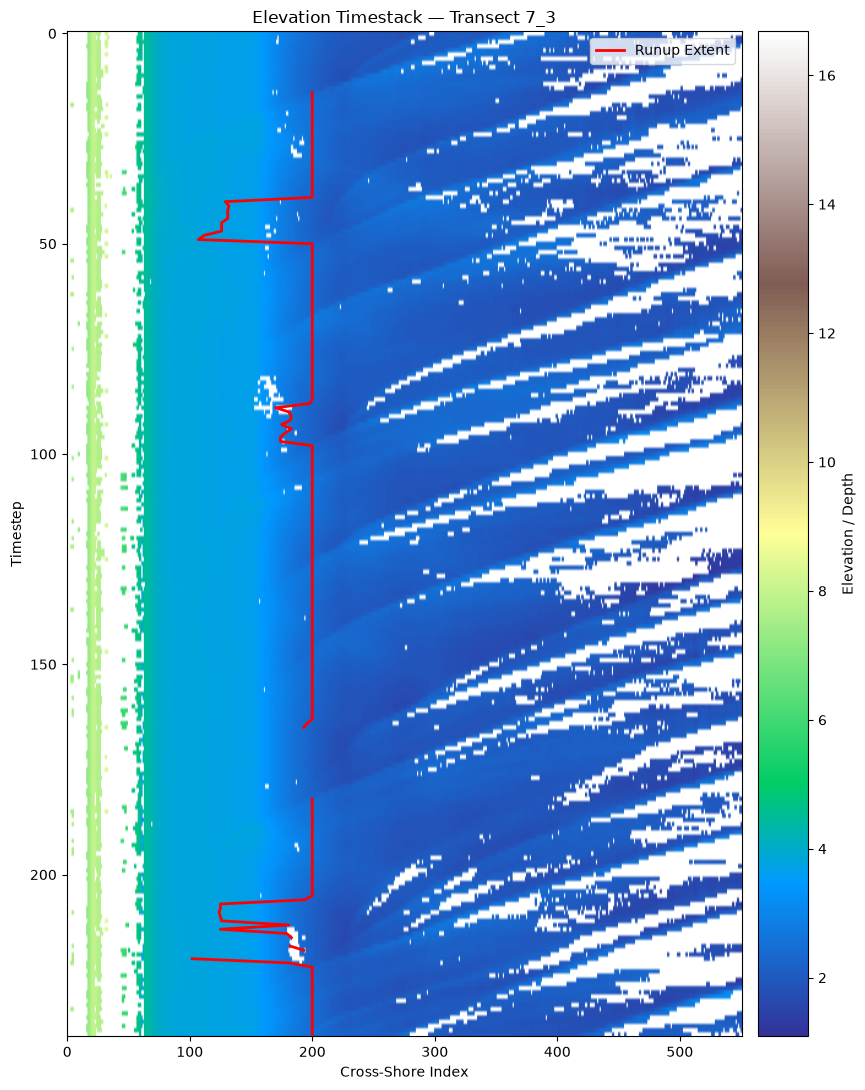

In [15]:
fig,ax=plot_elevation_timestack(transect=tran_7_3,runup=runup_7_3,cmap='terrain')
plt.show()